# Chapter 16: Reference Dependence, Losses, Ownership, and Regret

This notebook reruns four worked examples from the chapter: the selling and buying gap from loss aversion, regret overturning a better gamble, sunk costs in a continuation vote, and six bets judged together. Every example is hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def pct(fraction, digits=1):
    """Percent from a fraction: pct(0.022) -> '2.2%'."""
    return f"{num(100 * float(fraction), digits)}%"


def plural(count, singular, plural_form=None):
    """'1 trip', '3 trips', '0 trips'. Count is printed as an integer when whole."""
    word = singular if count == 1 else (plural_form or singular + "s")
    shown = str(int(count)) if float(count).is_integer() else str(count)
    return f"{shown} {word}"


def wta_wtp(v, lam):
    """loss-aversion: owner's WTA = lam * v, buyer's WTP = v, wedge = WTA - WTP.

    Book (ch016): v = 6, lam = 1.5 gives WTA 9, WTP 6, wedge 3.
    """
    wta = lam * v
    return {"wta": wta, "wtp": float(v), "wedge": wta - v}


def regret_score(probs, d, Q=None):
    """regret-theory: D = sum p_i Q(d_i), with the odd rule Q(d) = d^2 for d >= 0, -(-d)^2 for d < 0.

    Book (ch016): S = 50, gamble 65 (p 0.9) or 0: d = 15, -50; Q = 225, -2,500; D(G,S) = -47.5.
    Returns {"q": [...], "D": ...}.
    """
    if Q is None:
        Q = lambda x: x * x if x >= 0 else -((-x) ** 2)
    qs = [Q(x) for x in d]
    return {"q": qs, "D": sum(p * q for p, q in zip(probs, qs))}


def sunk_cost_score(B, C, sunk, alpha):
    """sunk-cost-effect: forward value B - C and behavioral score (B - C) + alpha * sunk.

    Book (ch016): B - C = 45,000 - 60,000 = -15,000; alpha 0.10 gives -13,000 (sunk 20,000) and 5,000 (200,000).
    """
    forward = B - C
    return {"forward": forward, "sunk_term": alpha * sunk, "score": forward + alpha * sunk}


def bundle_distribution(n, win, loss, p=0.5):
    """narrow-bracketing: distribution of total payoff win*h - loss*(n - h) over h ~ Binomial(n, p).

    Book (ch016): 6 bets of +120 / -100: each worth 10, bundle 60, total 220h - 600, loss probability 22/64 = 34.375%.
    Returns {"heads", "payoffs", "probs", "mean", "p_loss", "worst"}.
    """
    heads = list(range(n + 1))
    payoffs = [win * h - loss * (n - h) for h in heads]
    probs = [math.comb(n, h) * p ** h * (1 - p) ** (n - h) for h in heads]
    mean = sum(x * q for x, q in zip(payoffs, probs))
    p_loss = sum(q for x, q in zip(payoffs, probs) if x < 0)
    return {"heads": heads, "payoffs": payoffs, "probs": probs, "mean": mean, "p_loss": p_loss, "worst": payoffs[0]}


plt.rcParams.update(HOUSE_RC)


behavioral = SimpleNamespace(wta_wtp=wta_wtp, regret_score=regret_score, sunk_cost_score=sunk_cost_score, bundle_distribution=bundle_distribution)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'loss-aversion': {'v': 6, 'lam': 1.5, 'wta': 9, 'wtp': 6, 'wedge': 3, 'price': 7.5},
 'regret-theory': {'S': 50,
                   'good': 65,
                   'bad': 0,
                   'p': 0.9,
                   'EG': 58.5,
                   'q_good': 225,
                   'q_bad': -2500,
                   'D': -47.5},
 'sunk-cost-effect': {'B': 45000,
                      'C': 60000,
                      'alpha': 0.1,
                      'forward': -15000,
                      'sunk_X': 20000,
                      'score_X': -13000,
                      'sunk_Y': 200000,
                      'score_Y': 5000},
 'narrow-bracketing': {'win': 120,
                       'loss': 100,
                       'n': 6,
                       'ev_bet': 10,
                       'ev_bundle': 60,
                       'p_loss': 0.34375,
                       'worst': -600},
 'constructed': {'loss-aversion': {'lam': [2, 2.5], 'price': [5, 10]},
                 'regret-theory': {'S': [40, 45], 'p': [0.95, 0.99]},
                 'sunk-cost-effect': {'sunk': [100000], 'alpha': [0, 0.05, 0.2]},
                 'narrow-bracketing': {'n': [1, 12], 'win': [110, 150]}}}


def lam_text(lam):
    return num(lam, 1) if lam * 10 == int(lam * 10) and lam != int(lam) else num(lam, 0) if lam == int(lam) else num(lam, 2)


def price_text(p):
    return money(p, 0) if p == int(p) else money(p)


def wedge_picture(lam=1.5, price=7.50):
    v = BV["loss-aversion"]["v"]
    r = behavioral.wta_wtp(v, lam)
    wta, wtp, wedge = r["wta"], r["wtp"], r["wedge"]
    dana_sells = price >= wta
    eli_buys = price <= wtp
    fig, ax = new_figure()
    ax.axvspan(0, wtp, color=PALETTE["teal"], alpha=0.12)
    ax.axvspan(wta, 17, color=PALETTE["gold"], alpha=0.14)
    ax.plot([wtp, wta], [0.5, 0.5], color=PALETTE["terracotta"], linewidth=5, solid_capstyle="butt")
    if wedge == 0:
        mark(ax, wtp, 0.5, f"WTP = WTA = {money(wtp)}", col="ink", dx=-8, dy=12, ha="right")
    else:
        mark(ax, wtp, 0.5, f"WTP = {money(wtp)}", col="teal", dx=-8, dy=12, ha="right")
    if wedge:
        mark(ax, wta, 0.5, f"WTA = {money(wta)}", col="gold", dx=8 if wta < 13 else -8, dy=12, ha="left" if wta < 13 else "right")
    vline(ax, price, f"posted price {money(price)}", col="navy", y_frac=0.93, ha="left" if price < 12 else "right")
    label(ax, 0.4, 0.12, "Eli buys below WTP", col="teal", dx=0, dy=0, size=10.5)
    label(ax, 16.6, 0.12, "Dana sells above WTA", col="gold", dx=0, dy=0, ha="right", size=10.5)
    label(ax, (wtp + wta) / 2, 0.5, f"wedge {money(wedge)}" if wedge else "no wedge", col="terracotta", dx=0,
          dy=-22, ha="center", va="top")
    ax.set_xlim(0, 17)
    ax.set_ylim(0, 1)
    ax.set_yticks([])
    ax.set_xlabel("Price of the mug ($)")
    ax.set_ylabel("Thresholds")
    dana = "sells" if dana_sells else "keeps the mug"
    eli = "buys" if eli_buys else "declines"
    metrics = {"WTA (Dana, owner)": money(wta), "WTP (Eli, buyer)": money(wtp), "Wedge WTA - WTP": money(wedge),
               "Dana at the posted price": dana.capitalize(), "Eli at the posted price": eli.capitalize()}
    dana_why = (f"{money(price)} is at or above her {money(wta)} threshold, so Dana sells" if dana_sells
                else f"{money(price)} is below her {money(wta)} threshold, so Dana keeps the mug")
    eli_why = (f"{money(price)} is at or below his {money(wtp)} use value, so Eli buys" if eli_buys
               else f"{money(price)} is above his {money(wtp)} use value, so Eli declines")
    interp = (f"In dollars, WTA = {lam_text(lam)} x {v} = {num(wta)} and WTP = {money(wtp)}, a wedge of "
              f"{money(wta)} - {money(wtp)} = {money(wedge)}. At the posted price, {dana_why}; {eli_why}."
              + (" With lambda = 1 the asymmetry disappears." if lam == 1 else ""))
    steps = [f"WTA = {lam_text(lam)} x {money(v, 0)} = {money(wta)}",
             f"WTP = use value = {money(wtp)}",
             f"Wedge = {money(wta)} - {money(wtp)} = {money(wedge)}",
             f"Dana: {money(price)} {'>=' if dana_sells else '<'} {money(wta)}, so she {dana}",
             f"Eli: {money(price)} {'<=' if eli_buys else '>'} {money(wtp)}, so he {eli}"]
    alt = (f"A price line with the buyer's WTP at {money(wtp)} and the owner's WTA at {money(wta)}; the gap between "
           f"them is {money(wedge)}. The posted price {money(price)} is marked: Dana {dana} and Eli {eli}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def regret_picture(sure=50, p=0.9):
    S = sure
    b = BV["regret-theory"]
    good = b["good"]
    eg = p * good
    d_good, d_bad = good - S, 0 - S
    r = behavioral.regret_score([p, 1 - p], [d_good, d_bad])
    q_good, q_bad = r["q"]
    D = r["D"]
    q = 1 - p
    pick = "gamble" if D > 0 else "sure payment" if D < 0 else "tie"
    fig, (ax1, ax2) = new_figure(ncols=2)
    bar_compare(ax1, ["E[S]", "E[G]"], [S, eg], colors=["navy", "teal"],
                value_labels=[money(S), money(eg)], ylabel="Expected payoff ($)", xlabel="Option")
    bar_compare(ax2, ["p Q(good)", "(1-p) Q(bad)", "D(G,S)"], [p * q_good, q * q_bad, D],
                colors=["teal", "terracotta", "gold"],
                value_labels=[num(p * q_good), num(q * q_bad), num(D)], ylabel="Regret score", xlabel="Term")
    ax2.axhline(0, color=PALETTE["grey"], linewidth=1)
    metrics = {"E[S]": money(S), "E[G]": money(eg), "Q(good)": num(q_good, 0), "Q(bad)": num(q_bad, 0),
               "D(G,S)": num(D), "Choice": "Gamble" if D > 0 else "Sure payment"}
    interp = (f"E[G] = {num(p)} x 65 = {money(eg)}, above the sure {money(S)}. With both outcomes revealed, the good "
              f"state gives d = 65 - {S} = {d_good} and Q = {num(q_good, 0)}; the bad state gives d = 0 - {S} = "
              f"{d_bad} and Q = {num(q_bad, 0)}. D(G,S) = {num(p)} x {num(q_good, 0)} + {num(q)} x ({num(q_bad, 0)}) = "
              f"{num(p * q_good)} + ({num(q * q_bad)}) = {num(D)}, "
              + ("negative, so the chooser takes the sure payment despite the gamble's higher expected value."
                 if D < 0 else "positive, so the chooser takes the gamble."))
    steps = [f"E[G] = {num(p)} x 65 + {num(q)} x 0 = {money(eg)}",
             f"Good state: d = 65 - {S} = {d_good}, Q = {d_good} x {d_good} = {num(q_good, 0)}",
             f"Bad state: d = 0 - {S} = {d_bad}, Q = -({-d_bad} x {-d_bad}) = {num(q_bad, 0)}",
             f"D(G,S) = {num(p)} x {num(q_good, 0)} + {num(q)} x ({num(q_bad, 0)}) = {num(p * q_good)} + ({num(q * q_bad)}) = {num(D)}",
             f"D(G,S) {'<' if D < 0 else '>'} 0, so the chooser takes the {pick}"]
    alt = (f"Left: expected payoffs, sure {money(S)} against the gamble's {money(eg)}. Right: the regret terms "
           f"{num(p * q_good)} and {num(q * q_bad)} sum to D(G,S) = {num(D)}, so the chooser takes the {pick}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def sunk_picture(sunk=200_000, alpha=0.10):
    b = BV["sunk-cost-effect"]
    r = behavioral.sunk_cost_score(b["B"], b["C"], sunk, alpha)
    fwd, term, score = r["forward"], r["sunk_term"], r["score"]
    go = score > 0
    fig, ax = new_figure()
    bar_compare(ax, ["Forward value B - C", "Sunk-cost term", "Continuation score"], [fwd, term, score],
                colors=["terracotta", "gold", "navy"], value_labels=[money(fwd, 0), money(term, 0), money(score, 0)],
                ylabel="Dollars", xlabel="Component")
    ax.set_ylim(-20_000, 52_000)
    hline(ax, 0, col="grey")
    ax.text(0.98, 0.97, "continue only if the score is above zero", transform=ax.transAxes, ha="right", va="top",
            fontsize=11, color=PALETTE["ink"])
    metrics = {"Forward value B - C": money(fwd, 0), "Sunk-cost term": money(term, 0),
               "Continuation score": money(score, 0), "Committee decision": "Continue" if go else "Stop",
               "Rational decision": "Stop"}
    a = num(alpha, 2)
    interp = (f"B - C = $45,000 - $60,000 = {money(fwd, 0)} whatever was spent before. The committee adds "
              f"{a} x {num(sunk, 0)} = {num(term, 0)} dollars, so its score is {num(fwd, 0)} + {num(term, 0)} = "
              f"{num(score, 0)} and it " + ("continues, taking on an expected loss of $15,000." if go
                                              else "stops, as the forward-looking rule says."))
    steps = ["B - C = 45,000 - 60,000 = -15,000",
             f"Sunk-cost term = {a} x {num(sunk, 0)} = {num(term, 0)}",
             f"Score = -15,000 + {num(term, 0)} = {num(score, 0)}",
             f"Score {'>' if go else '<='} 0, so the committee {'continues' if go else 'stops'}"]
    alt = (f"Bars: forward value {money(fwd, 0)}, sunk-cost term {money(term, 0)} and continuation score "
           f"{money(score, 0)}; the committee {'continues' if go else 'stops'}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def bracket_picture(n=6, win=120):
    loss = BV["narrow-bracketing"]["loss"]
    r = behavioral.bundle_distribution(n, win, loss, 0.5)
    ev1 = 0.5 * win - 0.5 * loss
    losing = [h for h, x in zip(r["heads"], r["payoffs"]) if x < 0]
    hmax = max(losing)
    count = sum(__import__("math").comb(n, h) for h in losing)
    fig, ax = new_figure()
    cols = [PALETTE["terracotta"] if x < 0 else PALETTE["teal"] for x in r["payoffs"]]
    width = 0.7 * (win + loss)
    ax.bar(r["payoffs"], r["probs"], width=width, color=cols)
    ax.axvline(0, color=PALETTE["grey"], linewidth=1)
    top = max(r["probs"])
    ax.set_ylim(0, top * 1.25)
    ax.text(0.03, 0.95, f"red: total below zero, probability {pct(r['p_loss'], 3)}", transform=ax.transAxes,
            ha="left", va="top", fontsize=11, color=PALETTE["terracotta"], bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
    ax.text(0.97, 0.95, f"expected total {money(r['mean'], 0)}", transform=ax.transAxes, ha="right", va="top",
            fontsize=11, color=PALETTE["ink"])
    ax.set_xlabel("Total payoff of the bundle ($)")
    ax.set_ylabel("Probability")
    tails_min = n - hmax
    metrics = {"Expected value per bet": money(ev1), "Expected bundle total": money(r["mean"]),
               "Loss probability": pct(r["p_loss"], 3), "Worst case": money(r["worst"], 0),
               "Losing outcomes": f"{hmax} or fewer heads" if hmax else "0 heads"}
    interp = (f"Each bet is worth 0.5 x {win} - 0.5 x {loss} = {num(ev1)} dollars, so {n} {'bet is' if n == 1 else 'bets are'} "
              f"worth {n} x {num(ev1)} = {num(r['mean'])}. With h heads the total is {win}h - {loss}({n} - h) = "
              f"{win + loss}h - {num(loss * n, 0)}, which is negative {'only when h = 0' if hmax == 0 else f'when h is {hmax} or fewer'}. That happens in {num(count, 0)} "
              f"of 2^{n} = {num(2 ** n, 0)} equally likely sequences, a loss probability of {pct(r['p_loss'], 3)}; the "
              f"worst case is {money(r['worst'], 0)}.")
    steps = [f"Per bet: 0.5 x {win} - 0.5 x {loss} = {num(ev1)}",
             f"Bundle: {n} x {num(ev1)} = {num(r['mean'])}",
             f"Total with h heads: {win + loss}h - {num(loss * n, 0)}",
             f"Loss when h <= {hmax} (at least {plural(tails_min, 'tail')})",
             f"P(loss) = {num(count, 0)} / {num(2 ** n, 0)} = {pct(r['p_loss'], 3)}"]
    alt = (f"Distribution of the total payoff of {n} {'bet' if n == 1 else 'bets'} paying {win} or minus {loss}: "
           f"losing totals in red carry probability {pct(r['p_loss'], 3)}; the expected total is {money(r['mean'], 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Loss aversion: the loss-adjusted selling price

Dana owns a mug and Eli does not; both value using it at \$6. Giving up the mug is a loss weighted by $\lambda=1.5$.

$$\mathrm{WTA}=1.5(\$6)=\$9, \qquad \mathrm{WTP}=\$6, \qquad \$9-\$6=\$3$$

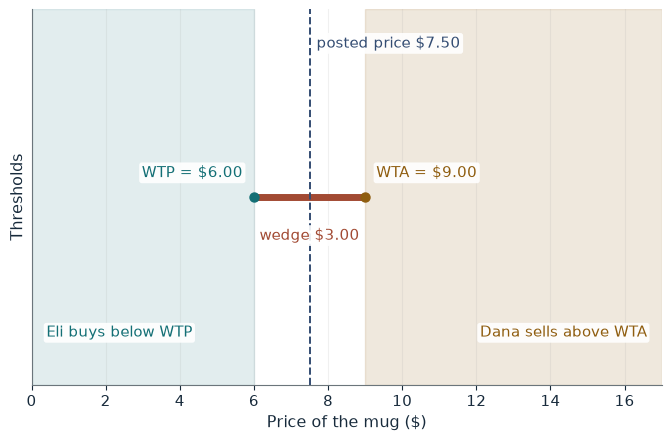

WTA (Dana, owner)         $9.00
WTP (Eli, buyer)          $6.00
Wedge WTA - WTP           $3.00
Dana at the posted price  Keeps the mug
Eli at the posted price   Declines

Worked steps:
  1. WTA = 1.5 x $6 = $9.00
  2. WTP = use value = $6.00
  3. Wedge = $9.00 - $6.00 = $3.00
  4. Dana: $7.50 < $9.00, so she keeps the mug
  5. Eli: $7.50 > $6.00, so he declines

In dollars, WTA = 1.5 x 6 = 9.00 and WTP = $6.00, a wedge of $9.00 - $6.00 = $3.00. At the posted price, $7.50 is below her $9.00 threshold, so Dana keeps the mug; $7.50 is above his $6.00 use value, so Eli declines.


In [2]:
show(wedge_picture(lam=1.5, price=7.50))

Change one input, `lam`, and hold the others at the book's values:

In [3]:
sweep(wedge_picture, 'lam', [1, 1.5, 2, 2.5], {'price': 7.5}, ['WTA (Dana, owner)', 'Wedge WTA - WTP', 'Dana at the posted price'])

lam | WTA (Dana, owner) | Wedge WTA - WTP | Dana at the posted price
1 | $6.00 | $0.00 | Sells
1.5 | $9.00 | $3.00 | Keeps the mug
2 | $12.00 | $6.00 | Keeps the mug
2.5 | $15.00 | $9.00 | Keeps the mug


At \$7.50 neither trades: Eli's use value is \$6 and Dana's threshold is \$9. With $\lambda=1$ her threshold falls to \$6 and she would sell.

## 2. Regret theory: regret beats a better gamble

A sure \$50 against a gamble paying \$65 with probability 0.9, else \$0. With $Q(d)=d^2$ for $d\geq0$ and $-(-d)^2$ for $d<0$:

$$E[G]=0.9(\$65)+0.1(\$0)=\$58.50, \qquad D(G,S)=0.9(225)+0.1(-2{,}500)=-47.5$$

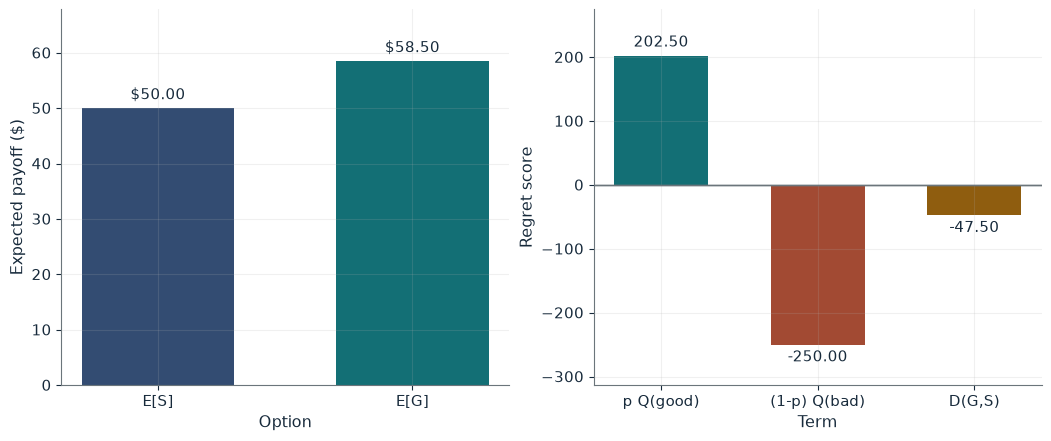

E[S]     $50.00
E[G]     $58.50
Q(good)  225
Q(bad)   -2,500
D(G,S)   -47.50
Choice   Sure payment

Worked steps:
  1. E[G] = 0.90 x 65 + 0.10 x 0 = $58.50
  2. Good state: d = 65 - 50 = 15, Q = 15 x 15 = 225
  3. Bad state: d = 0 - 50 = -50, Q = -(50 x 50) = -2,500
  4. D(G,S) = 0.90 x 225 + 0.10 x (-2,500) = 202.50 + (-250.00) = -47.50
  5. D(G,S) < 0, so the chooser takes the sure payment

E[G] = 0.90 x 65 = $58.50, above the sure $50.00. With both outcomes revealed, the good state gives d = 65 - 50 = 15 and Q = 225; the bad state gives d = 0 - 50 = -50 and Q = -2,500. D(G,S) = 0.90 x 225 + 0.10 x (-2,500) = 202.50 + (-250.00) = -47.50, negative, so the chooser takes the sure payment despite the gamble's higher expected value.


In [4]:
show(regret_picture(sure=50, p=0.9))

Change one input, `p`, and hold the others at the book's values:

In [5]:
sweep(regret_picture, 'p', [0.9, 0.95, 0.99], {'sure': 50}, ['E[G]', 'D(G,S)', 'Choice'])

p | E[G] | D(G,S) | Choice
0.9 | $58.50 | -47.50 | Sure payment
0.95 | $61.75 | 88.75 | Gamble
0.99 | $64.35 | 197.75 | Gamble


The negative score sends the chooser to the sure \$50 even though the gamble is worth \$8.50 more on average. At $p=0.95$ the score turns positive (88.75) and the gamble wins.

## 3. Sunk-cost effect: when history sneaks into the decision

Finishing a documentary costs \$60,000 and returns \$45,000; past spending is sunk. The committee adds $\alpha=0.10$ times past spending.

$$B-C=\$45{,}000-\$60{,}000=-\$15{,}000, \qquad -\$15{,}000+0.10(\$200{,}000)=\$5{,}000$$

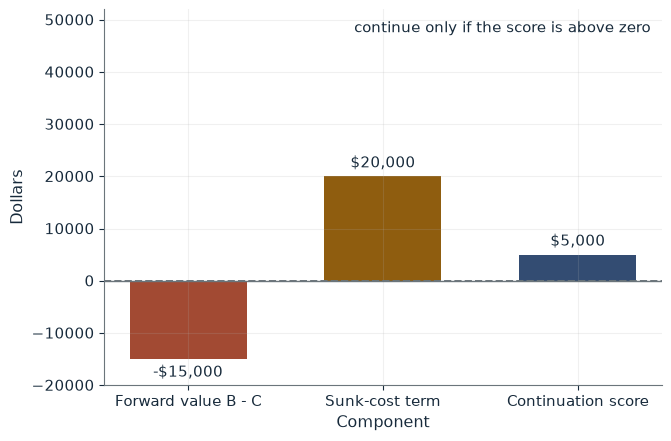

Forward value B - C  -$15,000
Sunk-cost term       $20,000
Continuation score   $5,000
Committee decision   Continue
Rational decision    Stop

Worked steps:
  1. B - C = 45,000 - 60,000 = -15,000
  2. Sunk-cost term = 0.10 x 200,000 = 20,000
  3. Score = -15,000 + 20,000 = 5,000
  4. Score > 0, so the committee continues

B - C = $45,000 - $60,000 = -$15,000 whatever was spent before. The committee adds 0.10 x 200,000 = 20,000 dollars, so its score is -15,000 + 20,000 = 5,000 and it continues, taking on an expected loss of $15,000.


In [6]:
show(sunk_picture(sunk=200_000, alpha=0.10))

Change one input, `sunk`, and hold the others at the book's values:

In [7]:
sweep(sunk_picture, 'sunk', [20000, 100000, 200000], {'alpha': 0.1}, ['Sunk-cost term', 'Continuation score', 'Committee decision'])

sunk | Sunk-cost term | Continuation score | Committee decision
20000 | $2,000 | -$13,000 | Stop
100000 | $10,000 | -$5,000 | Stop
200000 | $20,000 | $5,000 | Continue


The forward value is minus \$15,000 in every row, so the right decision is always to stop. Only the \$200,000 history pushes the score above zero; at \$150,000 it would be exactly zero.

## 4. Narrow bracketing: six bets as one portfolio

Each bet pays \$120 after heads and loses \$100 after tails on a fair coin.

$$0.5(\$120)-0.5(\$100)=\$10, \qquad 120h-100(6-h)=220h-600$$

The bundle loses only when $h\leq2$, with probability $22/64=34.375\%$.

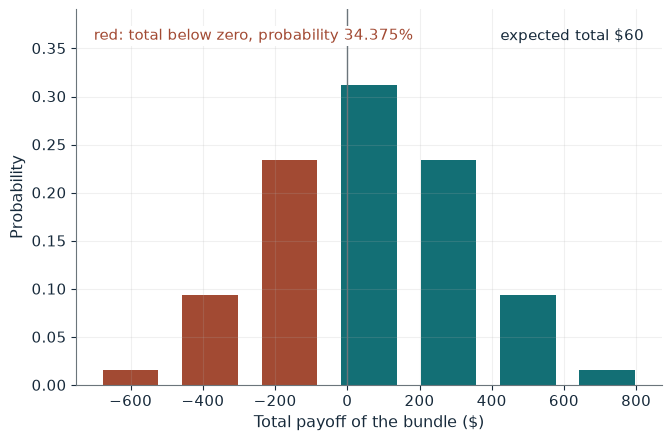

Expected value per bet  $10.00
Expected bundle total   $60.00
Loss probability        34.375%
Worst case              -$600
Losing outcomes         2 or fewer heads

Worked steps:
  1. Per bet: 0.5 x 120 - 0.5 x 100 = 10.00
  2. Bundle: 6 x 10.00 = 60.00
  3. Total with h heads: 220h - 600
  4. Loss when h <= 2 (at least 4 tails)
  5. P(loss) = 22 / 64 = 34.375%

Each bet is worth 0.5 x 120 - 0.5 x 100 = 10.00 dollars, so 6 bets are worth 6 x 10.00 = 60.00. With h heads the total is 120h - 100(6 - h) = 220h - 600, which is negative when h is 2 or fewer. That happens in 22 of 2^6 = 64 equally likely sequences, a loss probability of 34.375%; the worst case is -$600.


In [8]:
show(bracket_picture(n=6, win=120))

Change one input, `n`, and hold the others at the book's values:

In [9]:
sweep(bracket_picture, 'n', [1, 6, 12], {'win': 120}, ['Expected bundle total', 'Loss probability'])

n | Expected bundle total | Loss probability
1 | $10.00 | 50.000%
6 | $60.00 | 34.375%
12 | $120.00 | 38.721%


Six bets cut the loss probability from 50 percent to 34.375 percent. The path is not smooth: at 12 bets five heads still lose (220 x 5 - 1,200 = -100), so the loss probability is 38.721 percent, while the expected total doubles to \$120.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

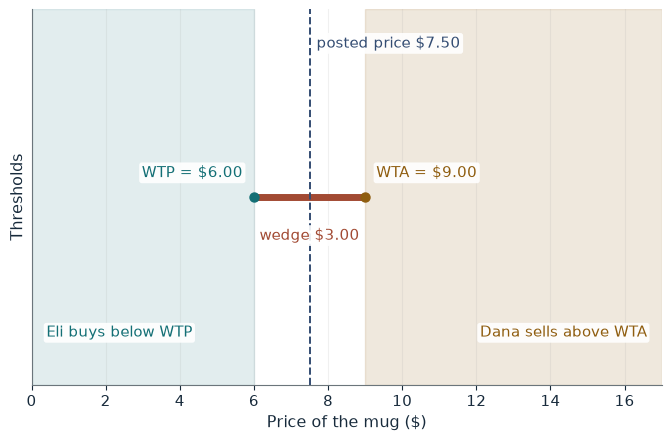

WTA (Dana, owner)         $9.00
WTP (Eli, buyer)          $6.00
Wedge WTA - WTP           $3.00
Dana at the posted price  Keeps the mug
Eli at the posted price   Declines

Worked steps:
  1. WTA = 1.5 x $6 = $9.00
  2. WTP = use value = $6.00
  3. Wedge = $9.00 - $6.00 = $3.00
  4. Dana: $7.50 < $9.00, so she keeps the mug
  5. Eli: $7.50 > $6.00, so he declines

In dollars, WTA = 1.5 x 6 = 9.00 and WTP = $6.00, a wedge of $9.00 - $6.00 = $3.00. At the posted price, $7.50 is below her $9.00 threshold, so Dana keeps the mug; $7.50 is above his $6.00 use value, so Eli declines.


In [10]:
show(wedge_picture(lam=1.5, price=7.50))

## Practice

**1.** With lambda = 2, what is the gap between Dana's selling price and Eli's buying price?

<details><summary>Answer</summary>

WTA = 2 x \$6 = \$12, so the wedge is \$12 - \$6 = \$6.

</details>

**2.** With a sure \$40 and p = 0.9, what is D(G,S), and which option is chosen?

<details><summary>Answer</summary>

d = 25 gives Q = 625; d = -40 gives Q = -1,600. D = 0.9 x 625 + 0.1 x (-1,600) = 562.5 - 160 = 402.5 > 0, so the gamble is chosen.

</details>

**3.** What past spending makes the alpha = 0.10 committee indifferent?

<details><summary>Answer</summary>

0.10 x S = 15,000, so S = \$150,000.

</details>